# Chapter 2 — Linear Associative Networks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mengrenman/artificial_intelligence_engines/blob/main/notebooks/02_linear_associative.ipynb)

*Companion notebook for Stone (2020), Chapter 2, using `scripts/linear.py`.*

A linear associative network has input units connected directly to output units, with a linear
activation, so the output for input $\mathbf{x}$ is $\mathbf{y} = W\mathbf{x}$. Given $T$ associations
$(\mathbf{x}_t, \mathsf{y}_t)$ we minimise the sum-of-squares error (Eq 2.24)

$$E = \frac12\sum_t (\mathbf{w}\cdot\mathbf{x}_t - \mathsf{y}_t)^2$$

by **gradient descent**: with the delta term $\delta_t = \mathbf{w}\cdot\mathbf{x}_t - \mathsf{y}_t$ (Eq 2.27),
the gradient is $\partial E/\partial w_i = \sum_t \delta_t x_{it}$ (Eq 2.29–2.30), and the weights change by
$\Delta\mathbf{w} = -\epsilon\nabla_{\mathbf{w}}E$ (Eq 2.32), the *delta rule* / Widrow–Hoff / LMS rule.

`LinearAssociativeNetwork` uses $E$ averaged over the $T$ associations (a constant factor $1/T$, which only rescales $\epsilon$).
`history[i]` is the error *before* update $i$.

In [1]:
# Colab setup: install the companion package (does nothing when run locally).
try:
    import google.colab  # noqa: F401
    %pip install -q git+https://github.com/mengrenman/artificial_intelligence_engines
except ImportError:
    pass

In [2]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scripts.linear import LinearAssociativeNetwork
from aie.losses import mean_sse
from aie.plotting import plot_error_surface

## Learning two associations (Section 2.5)

The network of Figure 2.5 has two inputs and one output, so two weights $w_1, w_2$. Two associations
give two simultaneous equations in two unknowns (Eq 2.19), so an exact solution usually exists, but we
find it by gradient descent. As in Figure 2.6 we start from $\mathbf{w} = (-0.8, -1.6)$.

In [3]:
X = np.array([[1.0, 0.4],
              [0.2, 1.0]])          # x_1, x_2 as rows
y = np.array([[1.0], [0.6]])         # targets
w_exact = np.linalg.solve(X, y).ravel()
print("exact solution w* =", w_exact.round(4))

net = LinearAssociativeNetwork(2, 1, lr=0.5)
net.W[:] = [[-0.8, -1.6]]
traj = [net.W.ravel().copy()]
for _ in range(60):                  # one update at a time to record the trajectory
    net.fit(X, y, n_epochs=1)
    traj.append(net.W.ravel().copy())
traj = np.array(traj)
print("learned w        =", net.W.ravel().round(4), f"  E = {net.error(X, y):.2e}")

exact solution w* = [0.8261 0.4348]
learned w        = [0.8261 0.4347]   E = 3.86e-10


### The error surface

Evaluating $E$ over a grid of $(w_1, w_2)$ gives a quadratic bowl (Figure 2.6). Gradient descent always
steps perpendicular to the contours, i.e. in the direction of steepest descent $-\nabla_{\mathbf{w}}E$.

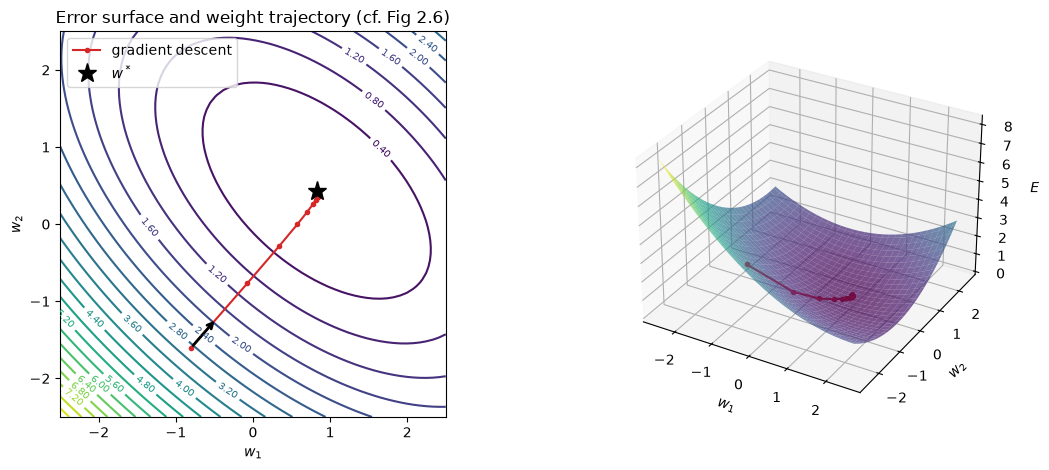

In [4]:
error_fn = lambda w: mean_sse(X @ w[:, None], y)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax, (W1g, W2g, Eg) = plot_error_surface(error_fn, w_range=(-2.5, 2.5), levels=25, ax=axes[0])
ax.plot(traj[:, 0], traj[:, 1], "o-", color="C3", ms=3, label="gradient descent")
ax.plot(*w_exact, "k*", ms=14, label="$w^*$")
g = (X.T @ (X @ traj[0][:, None] - y) / len(X)).ravel()
ax.annotate("", xy=traj[0] - 0.5 * g / np.linalg.norm(g), xytext=traj[0],
            arrowprops=dict(arrowstyle="->", lw=2))
ax.legend(); ax.set_title("Error surface and weight trajectory (cf. Fig 2.6)")
ax.set_aspect("equal")
ax3 = fig.add_subplot(1, 2, 2, projection="3d"); axes[1].remove()
ax3.plot_surface(W1g, W2g, Eg, cmap="viridis", alpha=0.7)
ax3.plot(traj[:, 0], traj[:, 1], [error_fn(w) for w in traj], "o-", color="C3", ms=3)
ax3.set_xlabel("$w_1$"); ax3.set_ylabel("$w_2$"); ax3.set_zlabel("$E$")
fig.tight_layout()

## The learning rate and the stability limit

For a linear network the error is exactly quadratic, $E(\mathbf{w}) = E(\mathbf{w}^*) + \tfrac12(\mathbf{w}-\mathbf{w}^*)^\top H(\mathbf{w}-\mathbf{w}^*)$,
with Hessian $H = \frac1T X^\top X$ (for the averaged error). A gradient step multiplies the component of
$\mathbf{w}-\mathbf{w}^*$ along each eigenvector of $H$ by $(1-\epsilon\lambda)$. Learning therefore converges
only if $|1-\epsilon\lambda_{\max}| < 1$, i.e.

$$\epsilon < \frac{2}{\lambda_{\max}} .$$

Below that limit, small $\epsilon$ is slow and larger $\epsilon$ is faster (possibly oscillating); above it,
the weights overshoot further on every step and $E$ explodes.

eigenvalues of H: [0.2485 0.8515]   stability limit 2/lambda_max = 2.349


Text(0.5, 1.0, 'Learning curves for different learning rates')

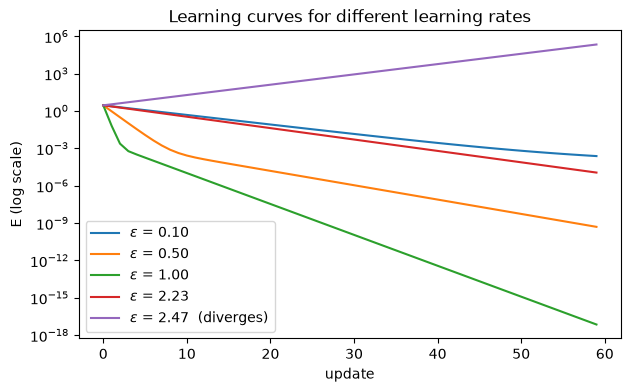

In [5]:
H = X.T @ X / len(X)
lam = np.linalg.eigvalsh(H)
lr_max = 2 / lam.max()
print("eigenvalues of H:", lam.round(4), f"  stability limit 2/lambda_max = {lr_max:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
for lr in [0.1, 0.5, 1.0, 0.95 * lr_max, 1.05 * lr_max]:
    n = LinearAssociativeNetwork(2, 1, lr=lr)
    n.W[:] = [[-0.8, -1.6]]
    n.fit(X, y, n_epochs=60)
    ax.semilogy(n.history, label=f"$\\epsilon$ = {lr:.2f}" + ("  (diverges)" if lr > lr_max else ""))
ax.set_xlabel("update"); ax.set_ylabel("E (log scale)"); ax.legend()
ax.set_title("Learning curves for different learning rates")

The curve just above $2/\lambda_{\max}$ grows without bound, while the one just below converges, but slowly,
because it oscillates back and forth across the valley. The smallest eigenvalue sets how slowly the
*shallowest* direction converges; the ratio $\lambda_{\max}/\lambda_{\min}$ (the condition number) is what
makes long, narrow valleys hard for plain gradient descent (Section 4.6).

## Learning many associations: recovering a weight matrix (Section 2.6)

With $I$ inputs and $K$ outputs the network has a $K\times I$ weight matrix and the same delta rule applies
to every weight, $\Delta w_{ki} = -\epsilon\sum_t \delta_{kt}x_{it}$. If the targets were generated by some
unknown linear map $W_{\text{true}}$, gradient descent recovers it.

max |W - W_true| = 4.440892098500626e-16


Text(0.5, 1.0, 'learning curve')

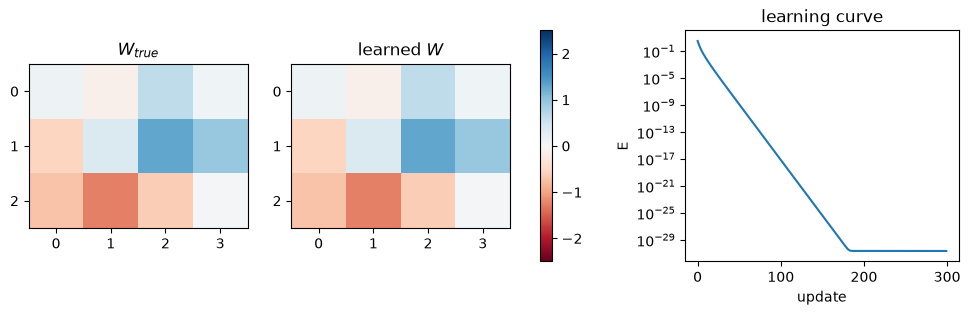

In [6]:
rng = np.random.default_rng(0)
W_true = rng.normal(size=(3, 4))
Xm = rng.normal(size=(50, 4))
Tm = Xm @ W_true.T
big = LinearAssociativeNetwork(4, 3, lr=0.3, seed=1).fit(Xm, Tm, n_epochs=300)
print("max |W - W_true| =", np.abs(big.W - W_true).max())
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, M_, ttl in zip(axes, [W_true, big.W], ["$W_{true}$", "learned $W$"]):
    im = ax.imshow(M_, cmap="RdBu", vmin=-2.5, vmax=2.5); ax.set_title(ttl)
fig.colorbar(im, ax=axes[:2])
axes[2].semilogy(big.history); axes[2].set_xlabel("update"); axes[2].set_ylabel("E")
axes[2].set_title("learning curve")

## The limitation: a linear network cannot learn XOR

The exclusive-OR associations (Eq 3.5–3.6) map $(\pm1, \pm1)$ to $-1$ when the inputs agree and $+1$ when
they differ. For a linear unit $y = w_1x_1 + w_2x_2$ (even with a bias), the targets are uncorrelated with
every input, so the least-squares solution is $\mathbf{w}=\mathbf{0}$: the network outputs $0$ for every
input and the error stays at $E=\tfrac12$ (averaged). No setting of the weights does better — it is not a
matter of training longer. Stacking more linear layers does not help either, because a product of
matrices is still a single matrix. This motivates the nonlinear perceptron (Chapter 3) and hidden units (Chapter 4).

In [7]:
from aie.data import xor_dataset
Xx, tx = xor_dataset()
Xb = np.hstack([Xx, np.ones((4, 1))])          # add a bias input to be generous
lin = LinearAssociativeNetwork(3, 1, lr=0.2).fit(Xb, tx[:, None], n_epochs=200)
print("weights (w1, w2, bias):", lin.W.ravel().round(4))
for x, t_, out in zip(Xx, tx, lin.predict(Xb).ravel()):
    print(f"x = {x}  target = {t_:+.0f}  output = {out:+.4f}")
print(f"final E = {lin.history[-1]:.4f}  (best possible for a linear net: 0.5)")

weights (w1, w2, bias): [-0. -0.  0.]
x = [-1. -1.]  target = -1  output = +0.0000
x = [1. 1.]  target = -1  output = +0.0000
x = [-1.  1.]  target = +1  output = +0.0000
x = [ 1. -1.]  target = +1  output = +0.0000
final E = 0.5000  (best possible for a linear net: 0.5)


## Summary

* A linear associative network computes $\mathbf{y} = W\mathbf{x}$; its sum-of-squares error is a quadratic bowl.
* Gradient descent with the delta rule (Eq 2.32) slides down the bowl to the least-squares solution.
* The learning rate must satisfy $\epsilon < 2/\lambda_{\max}$ or learning diverges.
* Linear networks can only learn linear mappings — XOR is out of reach.